In [1]:
%pip install numpy pandas matplotlib scipy scikit-learn statsmodels openpyxl
import os
print('carpeta actual:', os.getcwd())
print(os.listdir())

Note: you may need to restart the kernel to use updated packages.
carpeta actual: C:\Users\Dell Inspiron 14\Tarea 4
['.ipynb_checkpoints', 'bitacora.csv', 'bitacora_inicial.csv', 'figuras', 'fig_pronosticos.png', 'indice_estacional.csv', 'limpiar.py', 'Online Retail.xlsx', 'retail.pkl', 'rfm.csv', 'tabla02.csv', 'tabla04.csv', 'tabla5.csv', 'Untitled.ipynb', '__pycache__']



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
def acf(y, K):
    y = np.asarray(y, float); n = len(y); d = y - y.mean(); den = (d**2).sum()
    return np.array([(d[k:] * d[:n-k]).sum() / den for k in range(1, K+1)])

def ljung_box(y, m, n_par=0):
    n = len(y); r = acf(y, m)
    Q = n*(n+2)*np.sum(r**2 / (n - np.arange(1, m+1)))
    return Q, stats.chi2.sf(Q, m - n_par)

def sim_ar1(phi, reps=1, n=300, burn=200, c=0.0, sigma=1.0, rng=None):
    e = rng.normal(0, sigma, (reps, n+burn)); y = np.zeros((reps, n+burn))
    for t in range(1, n+burn):
        y[:, t] = c + phi*y[:, t-1] + e[:, t]
    return y[:, burn:]

print('funciones base listas')

funciones base listas


In [3]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from scipy import stats
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
warnings.filterwarnings("ignore")
plt.rcParams['figure.figsize'] = (9, 3.5)
os.makedirs('figuras', exist_ok=True)

def guardar(nombre):
    plt.savefig(f'figuras/{nombre}.png', dpi=150, bbox_inches='tight')

In [4]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from scipy import stats
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
warnings.filterwarnings("ignore")
plt.rcParams['figure.figsize'] = (9, 3.5)

# guarda cada figura automáticamente en /figuras
os.makedirs('figuras', exist_ok=True)
_show = plt.show; _n = [0]
def show_y_guardar(*a, **k):
    _n[0] += 1
    plt.savefig(f'figuras/fig_{_n[0]:02d}.png', dpi=150, bbox_inches='tight')
    _show(*a, **k)
plt.show = show_y_guardar
print('imports listos')

imports listos


In [5]:
for nombre in ['np', 'acf', 'ljung_box', 'sim_ar1', 'resumen', 'SARIMAX']:
    print(nombre, nombre in globals())

np True
acf True
ljung_box True
sim_ar1 True
resumen False
SARIMAX True


In [6]:
def stats_reps(Y, m=10):
    R, n = Y.shape
    d = Y - Y.mean(1, keepdims=True); den = (d**2).sum(1)
    r = np.column_stack([(d[:, k:]*d[:, :n-k]).sum(1)/den for k in range(1, m+1)])
    x, z = Y[:, :-1], Y[:, 1:]
    xc = x - x.mean(1, keepdims=True); zc = z - z.mean(1, keepdims=True)
    phi_hat = (xc*zc).sum(1) / (xc**2).sum(1)          # OLS con intercepto
    Q = n*(n+2)*(r**2 / (n - np.arange(1, m+1))).sum(1)
    return dict(r1=r[:, 0], r5=r[:, 4], r7=r[:, 6],
                rej1=(np.abs(r[:, 0]) > 1.96/np.sqrt(n)).astype(float),
                rejLB=(stats.chi2.sf(Q, m) < 0.05).astype(float),
                phi_hat=phi_hat)

def resumen(Y, nombre, r5_teo=np.nan):
    s = stats_reps(Y); R = len(Y); out = {'escenario': nombre, 'r5_teorico': r5_teo}
    for k, v in s.items():
        out[k] = v.mean(); out['ee_'+k] = v.std(ddof=1)/np.sqrt(R)
    return out

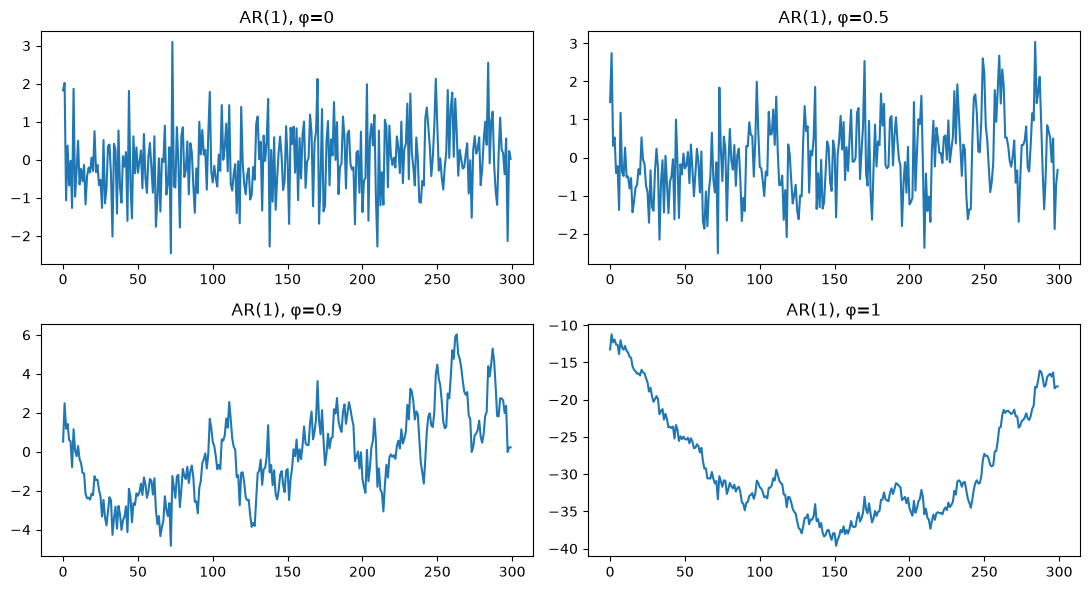

,r1,ee_r1,r5,ee_r5,r5_teorico,rej1,ee_rej1,phi_hat,ee_phi_hat
escenario,,,,,,,,,
AR1 φ=0,-0.003491,0.000827,-0.002905,0.000804,0.00000,0.0498,0.003077,-0.003495,0.000829
AR1 φ=0.5,0.490839,0.000710,0.018137,0.001017,0.03125,1.0000,0.000000,0.492551,0.000712
AR1 φ=0.9,0.883286,0.000400,0.532695,0.001423,0.59049,1.0000,0.000000,0.886509,0.000396
AR1 φ=1,0.975487,0.000209,0.881910,0.000942,1.00000,1.0000,0.000000,0.981973,0.000215


In [7]:
# Una realización de cada phi
fig, ax = plt.subplots(2, 2, figsize=(11, 6))
for a, phi in zip(ax.ravel(), [0, 0.5, 0.9, 1]):
    a.plot(sim_ar1(phi, rng=np.random.default_rng(1))[0]); a.set_title(f'AR(1), φ={phi}')
plt.tight_layout(); plt.show()

# 5000 réplicas, semilla distinta por escenario
R = 5000; filas = []
for i, phi in enumerate([0, 0.5, 0.9, 1]):
    rng = np.random.default_rng(100+i)
    filas.append(resumen(sim_ar1(phi, R, rng=rng), f'AR1 φ={phi}', phi**5))
tabla02 = pd.DataFrame(filas).set_index('escenario')
display(tabla02[['r1','ee_r1','r5','ee_r5','r5_teorico','rej1','ee_rej1','phi_hat','ee_phi_hat']])

In [8]:
t = np.arange(1, 301)
medias = {'(a) tendencia': 2*t/300,
          '(b) semanal': np.where(t % 7 == 6, -1.5, 0.25)}
filas = []
for j, (nom, m) in enumerate(medias.items()):
    rng = np.random.default_rng(200+j)
    filas.append(resumen(m + rng.normal(size=(R, 300)), nom))
rng = np.random.default_rng(300)
filas.append(resumen(rng.normal(size=(R, 300)), 'ruido blanco (φ=0)'))
tabla04 = pd.DataFrame(filas).set_index('escenario')
display(tabla04[['r1','rej1','ee_rej1','r7','ee_r7','rejLB','ee_rejLB']])

# Verificación de mi Ljung-Box contra statsmodels
y = np.random.default_rng(5).normal(size=300)
print(ljung_box(y, 10), acorr_ljungbox(y, lags=[10]))

,r1,rej1,ee_rej1,r7,ee_r7,rejLB,ee_rejLB
escenario,,,,,,,
(a) tendencia,0.245198,0.9822,0.001870,0.230659,0.000819,1.0000,0.000000
(b) semanal,-0.048201,0.1170,0.004546,0.265660,0.000833,0.9522,0.003017
ruido blanco (φ=0),-0.003196,0.0502,0.003088,-0.003122,0.000803,0.0512,0.003117


(np.float64(18.13939463998863), np.float64(0.05265728499446809))       lb_stat  lb_pvalue
10  18.139395   0.052657


In [9]:
%%writefile limpiar.py
import pandas as pd


def _monto(d):
    return float((d.Quantity * d.UnitPrice).sum())


def limpiar(df, devolver_bitacora=False, conservar_creditos_M=True):
    """Limpia el DataFrame de Online Retail y lo devuelve (conserva el índice original).

    Reglas, en este orden (el orden cambia los conteos de la bitácora):
      1. duplicados exactos
      2. facturas cuyo número no empieza con dígito ni con C (las 'A' = ajuste de deuda)
      3. StockCode que no es producto (no empieza con 5 dígitos ni con DCGS).
         Si conservar_creditos_M=True se salvan las filas 'M' (Manual) de facturas C.
      4. UnitPrice <= 0
      5. Quantity < 0 en facturas que no son cancelaciones

    NO elimina las filas sin CustomerID: se necesitan para la serie de ventas.
    """
    d = df.copy()
    bit = []

    def regla(nombre, mask):
        nonlocal d
        bit.append({'regla': nombre, 'filas': int(mask.sum()), 'monto_£': _monto(d[mask])})
        d = d[~mask]

    regla('1. duplicados exactos', d.duplicated(keep='first'))
    regla('2. factura que no empieza con dígito ni C (las A, ajuste de deuda)',
          ~d.InvoiceNo.str.match(r'^[0-9C]'))
    no_producto = ~d.StockCode.str.match(r'^(\d{5}|DCGS)')
    if conservar_creditos_M:
        no_producto = no_producto & ~((d.StockCode == 'M') & d.InvoiceNo.str.startswith('C'))
    regla('3. StockCode que no es producto' +
          (' (salvo créditos M de facturas C)' if conservar_creditos_M else ''), no_producto)
    regla('4. UnitPrice <= 0', d.UnitPrice <= 0)
    regla('5. Quantity < 0 en factura que no es cancelación',
          (d.Quantity < 0) & ~d.InvoiceNo.str.startswith('C'))
    return (d, pd.DataFrame(bit)) if devolver_bitacora else d

Overwriting limpiar.py


In [10]:
from limpiar import limpiar
df = pd.read_excel('Online Retail.xlsx',
                   dtype={'InvoiceNo': str, 'StockCode': str, 'CustomerID': str})
df['CustomerID'] = df.CustomerID.str.replace(r'\.0$', '', regex=True)
print(len(df), df.InvoiceNo.nunique(), df.StockCode.nunique(), df.CustomerID.nunique())

541909 25900 4070 4372


In [11]:
# (a) duplicados exactos
print('duplicados:', df.duplicated().sum())

# (b) facturas que no empiezan con dígito
print(df[~df.InvoiceNo.str[0].str.isdigit()].InvoiceNo.str[0].value_counts())

# (d) precios cero y negativos
print('precio == 0:', (df.UnitPrice == 0).sum(), '| precio < 0:', (df.UnitPrice < 0).sum())
print(df[df.UnitPrice == 0].Description.value_counts().head(10))
print('sin CustomerID entre precio 0:', df[df.UnitPrice == 0].CustomerID.isna().mean())

duplicados: 5268
InvoiceNo
C    9288
A       3
Name: count, dtype: int64
precio == 0: 2515 | precio < 0: 2
Description
check                            159
?                                 47
damages                           45
damaged                           43
found                             25
sold as set on dotcom             20
adjustment                        16
Damaged                           14
FRENCH BLUE METAL DOOR SIGN 1      9
thrown away                        9
Name: count, dtype: int64
sin CustomerID entre precio 0: 0.9840954274353877


In [12]:
# (e) cantidades negativas en facturas que NO son cancelaciones
neg = df[(df.Quantity < 0) & ~df.InvoiceNo.str.startswith('C')]
print('filas:', len(neg))
print(neg.Description.value_counts().head(12))
print(neg.UnitPrice.describe())

# (f) filas sin CustomerID
sin = df[df.CustomerID.isna()]
print('facturas sin cliente:', sin.InvoiceNo.nunique(), '| monto £:', (sin.Quantity*sin.UnitPrice).sum().round(0))
print('monto total £:', (df.Quantity*df.UnitPrice).sum().round(0))

filas: 1336
Description
check                     120
damages                    45
damaged                    42
?                          41
sold as set on dotcom      20
Damaged                    14
thrown away                 9
Unsaleable, destroyed.      9
??                          7
damages?                    5
wet damaged                 5
ebay                        5
Name: count, dtype: int64
count    1336.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: UnitPrice, dtype: float64
facturas sin cliente: 3710 | monto £: 1447682.0
monto total £: 9747748.0


In [13]:
limpio0, bitacora0 = limpiar(df, devolver_bitacora=True, conservar_creditos_M=False)
display(bitacora0); print('versión inicial:', len(df), '->', len(limpio0))
limpio, bitacora = limpiar(df, devolver_bitacora=True)
display(bitacora); print('versión final:', len(df), '->', len(limpio))
bitacora0.to_csv('bitacora_inicial.csv', index=False); bitacora.to_csv('bitacora.csv', index=False)

,regla,filas,monto_£
0,1. duplicados exactos,5268,21740.980
1,2. factura que no empieza con dígito ni C (las...,3,-11062.060
2,3. StockCode que no es producto,2941,-34249.146
3,4. UnitPrice <= 0,2492,0.000
4,5. Quantity < 0 en factura que no es cancelación,0,0.000


versión inicial: 541909 -> 531205


,regla,filas,monto_£
0,1. duplicados exactos,5268,21740.980
1,2. factura que no empieza con dígito ni C (las...,3,-11062.060
2,3. StockCode que no es producto (salvo crédito...,2697,112535.314
3,4. UnitPrice <= 0,2492,0.000
4,5. Quantity < 0 en factura que no es cancelación,0,0.000


versión final: 541909 -> 531449


In [14]:
limpio, bitacora = limpiar(df, devolver_bitacora=True)
display(bitacora)
print('filas antes:', len(df), '| después:', len(limpio))
bitacora.to_csv('bitacora.csv', index=False)

,regla,filas,monto_£
0,1. duplicados exactos,5268,21740.980
1,2. factura que no empieza con dígito ni C (las...,3,-11062.060
2,3. StockCode que no es producto (salvo crédito...,2697,112535.314
3,4. UnitPrice <= 0,2492,0.000
4,5. Quantity < 0 en factura que no es cancelación,0,0.000


filas antes: 541909 | después: 531449


In [15]:
raw = df.assign(monto=df.Quantity*df.UnitPrice)
top = raw.loc[raw.monto.abs().sort_values(ascending=False).index[:6]]
display(top)
for i, row in top.iterrows():
    ventana = raw[(raw.StockCode == row.StockCode) &
                  raw.InvoiceDate.between(row.InvoiceDate - pd.Timedelta(days=1),
                                          row.InvoiceDate + pd.Timedelta(days=7)) &
                  (raw.Quantity.abs() == abs(row.Quantity))]
    print(f'\n--- fila {i}: {row.InvoiceNo} {row.Description} monto={row.monto:,.0f}')
    display(ventana[['InvoiceNo','InvoiceDate','Quantity','UnitPrice','CustomerID']])
    print('¿sobrevive a limpiar()?', i in limpio.index)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,monto
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446,United Kingdom,-168469.6
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom,168469.6
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,United Kingdom,-77183.6
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom,77183.6
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098,United Kingdom,-38970.0
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,15098,United Kingdom,38970.0



--- fila 540422: C581484 PAPER CRAFT , LITTLE BIRDIE monto=-168,470


,InvoiceNo,InvoiceDate,Quantity,UnitPrice,CustomerID
540421,581483,2011-12-09 09:15:00,80995,2.08,16446
540422,C581484,2011-12-09 09:27:00,-80995,2.08,16446


¿sobrevive a limpiar()? True

--- fila 540421: 581483 PAPER CRAFT , LITTLE BIRDIE monto=168,470


,InvoiceNo,InvoiceDate,Quantity,UnitPrice,CustomerID
540421,581483,2011-12-09 09:15:00,80995,2.08,16446
540422,C581484,2011-12-09 09:27:00,-80995,2.08,16446


...

¿sobrevive a limpiar()? True

--- fila 222681: C556445 Manual monto=-38,970


,InvoiceNo,InvoiceDate,Quantity,UnitPrice,CustomerID
221764,C556274,2011-06-09 19:46:00,-1,600.00,15299
222681,C556445,2011-06-10 15:31:00,-1,38970.00,15098
224707,556573,2011-06-13 13:32:00,1,4.25,14667
225406,556671,2011-06-13 16:33:00,1,2.50,17841
225431,C556675,2011-06-13 17:13:00,-1,20.00,16013
226258,556784,2011-06-14 13:15:00,1,0.39,14461
226499,C556807,2011-06-14 15:43:00,-1,91.58,NaN
227399,C556870,2011-06-15 11:47:00,-1,306.60,NaN
227401,C556875,2011-06-15 11:51:00,-1,702.38,NaN


¿sobrevive a limpiar()? True

--- fila 222680: 556444 PICNIC BASKET WICKER 60 PIECES monto=38,970


,InvoiceNo,InvoiceDate,Quantity,UnitPrice,CustomerID
222670,556442,2011-06-10 15:22:00,60,4.95,15098
222680,556444,2011-06-10 15:28:00,60,649.50,15098
222692,C556448,2011-06-10 15:39:00,-60,4.95,15098


¿sobrevive a limpiar()? True


In [16]:
m_c = df[(df.StockCode == 'M') & df.InvoiceNo.str.startswith('C')]
print('filas M con factura C:', len(m_c), '| monto £:', (m_c.Quantity*m_c.UnitPrice).sum().round(0))
print(m_c.assign(monto=m_c.Quantity*m_c.UnitPrice).nsmallest(5, 'monto')[['InvoiceNo','InvoiceDate','UnitPrice','CustomerID']])

filas M con factura C: 244 | monto £: -146784.0
       InvoiceNo         InvoiceDate  UnitPrice CustomerID
222681   C556445 2011-06-10 15:31:00   38970.00      15098
422375   C573079 2011-10-27 14:15:00    4161.06      12536
173391   C551699 2011-05-03 14:12:00    6930.00      16029
268027   C560372 2011-07-18 12:26:00    4287.63      17448
406404   C571750 2011-10-19 11:16:00    3949.32      12744


In [17]:
limpio['monto'] = limpio.Quantity * limpio.UnitPrice
diaria = limpio.groupby(limpio.InvoiceDate.dt.normalize()).monto.sum()
cal = pd.date_range(diaria.index.min(), diaria.index.max(), freq='D')
print('días calendario:', len(cal), '| con transacción:', len(diaria))
faltan = cal[~cal.isin(diaria.index)]
tab = pd.DataFrame({'fecha': faltan, 'dia': faltan.day_name()})
print(tab.dia.value_counts())
display(tab[tab.dia != 'Saturday'])
print(limpio.InvoiceDate.max()); print(diaria.tail(3))
print(diaria['2011-06-07':'2011-06-14'])

días calendario: 374 | con transacción: 305
dia
Saturday     53
Monday        6
Friday        4
Sunday        3
Tuesday       1
Wednesday     1
Thursday      1
Name: count, dtype: int64


,fecha,dia
3,2010-12-24,Friday
5,2010-12-26,Sunday
6,2010-12-27,Monday
7,2010-12-28,Tuesday
8,2010-12-29,Wednesday
9,2010-12-30,Thursday
10,2010-12-31,Friday
12,2011-01-02,Sunday
13,2011-01-03,Monday
29,2011-04-22,Friday


2011-12-09 12:50:00
InvoiceDate
2011-12-07    72436.15
2011-12-08    76485.64
2011-12-09    29305.57
Name: monto, dtype: float64
InvoiceDate
2011-06-07    36869.44
2011-06-08    40427.94
2011-06-09    44413.03
2011-06-10    21937.45
2011-06-12    12318.74
2011-06-13    19407.35
2011-06-14    39835.76
Name: monto, dtype: float64


In [18]:
%%writefile limpiar.py
import pandas as pd

def _monto(d): return float((d.Quantity * d.UnitPrice).sum())

def limpiar(df, devolver_bitacora=False):
    """Devuelve df limpio (conserva índice original). NO elimina filas sin CustomerID
    (se necesitan para la serie de ventas; la Parte 6 las quita aparte)."""
    d = df.copy(); bit = []
    def regla(nombre, mask):
        nonlocal d
        bit.append({'regla': nombre, 'filas': int(mask.sum()), 'monto_£': _monto(d[mask])})
        d = d[~mask]
    regla('1. duplicados exactos', d.duplicated(keep='first'))
    regla('2. factura con prefijo distinto de dígito/C (ej. A = ajuste deuda)',
          ~d.InvoiceNo.str.match(r'^[0-9C]'))
    regla('3. StockCode no producto (salvo créditos M con factura C)',
          ~d.StockCode.str.match(r'^(\d{5}|DCGS)')
          & ~((d.StockCode == 'M') & d.InvoiceNo.str.startswith('C')))
    regla('4. UnitPrice <= 0', d.UnitPrice <= 0)
    regla('5. Quantity < 0 en factura que no es cancelación',
          (d.Quantity < 0) & ~d.InvoiceNo.str.startswith('C'))
    return (d, pd.DataFrame(bit)) if devolver_bitacora else d

Overwriting limpiar.py


In [19]:
import importlib, limpiar as lm
importlib.reload(lm); limpiar = lm.limpiar
limpio, bitacora = limpiar(df, devolver_bitacora=True)
display(bitacora); print(len(df), len(limpio))
bitacora.to_csv('bitacora.csv', index=False)

# repetir la Parte 2 con la limpieza nueva
limpio['monto'] = limpio.Quantity * limpio.UnitPrice
diaria = limpio.groupby(limpio.InvoiceDate.dt.normalize()).monto.sum()
cal = pd.date_range(diaria.index.min(), diaria.index.max(), freq='D')
print('días calendario:', len(cal), '| con transacción:', len(diaria))
print(diaria['2011-06-07':'2011-06-14'])

,regla,filas,monto_£
0,1. duplicados exactos,5268,21740.980
1,2. factura con prefijo distinto de dígito/C (e...,3,-11062.060
2,3. StockCode no producto (salvo créditos M con...,2697,112535.314
3,4. UnitPrice <= 0,2492,0.000
4,5. Quantity < 0 en factura que no es cancelación,0,0.000


541909 531449
días calendario: 374 | con transacción: 305
InvoiceDate
2011-06-07    36869.44
2011-06-08    40427.94
2011-06-09    44413.03
2011-06-10    21937.45
2011-06-12    12318.74
2011-06-13    19407.35
2011-06-14    39835.76
Name: monto, dtype: float64


In [20]:
serie = diaria.reindex(cal).iloc[:-1]
FIN_TRAIN, FIN = pd.Timestamp('2011-09-30'), pd.Timestamp('2011-12-08')
A = serie.dropna()
print(len(serie), len(A), (A <= 0).sum(), A.min())
print(diaria.tail(3))

373 304 0 3439.67
InvoiceDate
2011-12-07    72436.15
2011-12-08    76485.64
2011-12-09    29305.57
Name: monto, dtype: float64


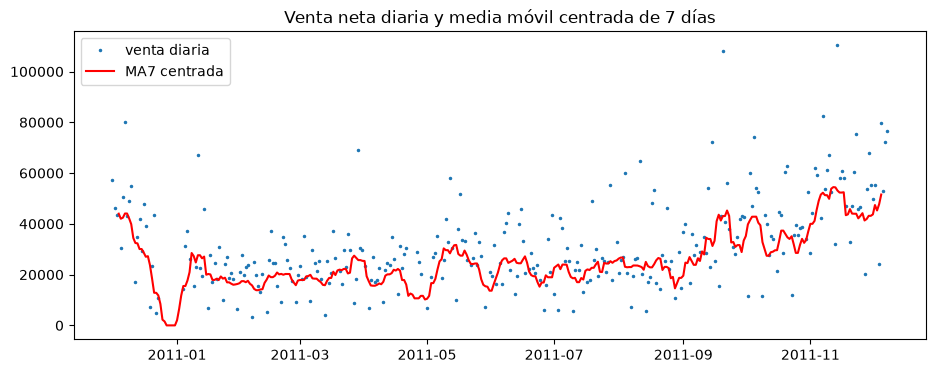

In [21]:
ma = serie.fillna(0).rolling(7, center=True).mean()
plt.figure(figsize=(11, 4))
plt.plot(serie, '.', ms=3, label='venta diaria'); plt.plot(ma, 'r', label='MA7 centrada')
plt.legend(); plt.title('Venta neta diaria y media móvil centrada de 7 días'); plt.show()

,índice
Lun,1.141
Mar,1.547
Mié,1.238
Jue,1.568
Vie,1.118
Dom,0.584


promedio de los 6 índices: 1.1994567974847983


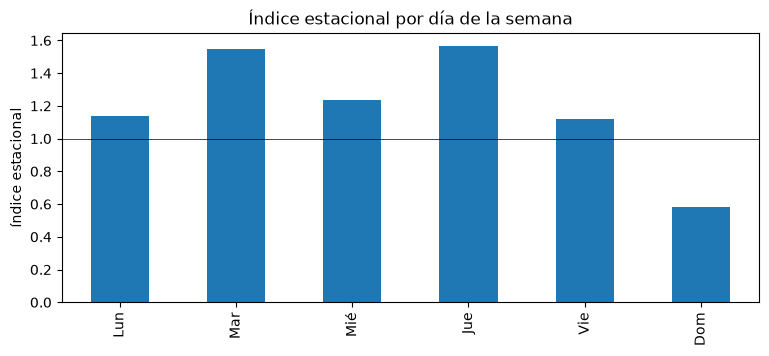

In [22]:
ratio = (serie / ma)[serie.index <= FIN_TRAIN].dropna()
idx_est = ratio.groupby(ratio.index.dayofweek).mean()
idx_est.index = ['Lun','Mar','Mié','Jue','Vie','Dom']
display(idx_est.round(3).to_frame('índice'))
print('promedio de los 6 índices:', idx_est.mean())
idx_est.plot.bar(); plt.axhline(1, c='k', lw=.5); plt.ylabel('índice estacional')
plt.title('Índice estacional por día de la semana'); plt.show()
idx_est.round(3).to_csv('indice_estacional.csv')

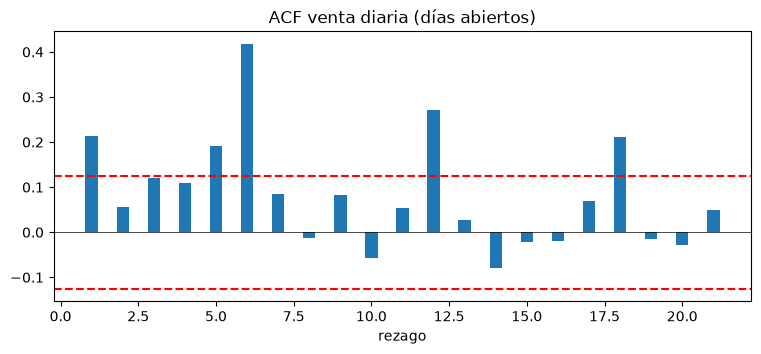

n = 245 | fuera de banda: 5 | lag1 rechaza: True
pico en rezago 6
Q6 (np.float64(72.09594683530968), np.float64(1.5183758114122899e-13)) Q12 (np.float64(96.53304669858268), np.float64(2.6518862861494193e-15))


In [23]:
tr = A[A.index <= FIN_TRAIN]; y = tr.values; n = len(y)
def plot_acf(r, n, titulo):
    k = np.arange(1, len(r)+1); b = 1.96/np.sqrt(n)
    plt.bar(k, r, width=.4); plt.axhline(b, ls='--', c='r'); plt.axhline(-b, ls='--', c='r')
    plt.axhline(0, c='k', lw=.5); plt.xlabel('rezago'); plt.title(titulo); plt.show()
r = acf(y, 21); plot_acf(r, n, 'ACF venta diaria (días abiertos)')
print('n =', n, '| fuera de banda:', (np.abs(r) > 1.96/np.sqrt(n)).sum(), '| lag1 rechaza:', abs(r[0]) > 1.96/np.sqrt(n))
print('pico en rezago', r.argmax()+1)
print('Q6', ljung_box(y, 6), 'Q12', ljung_box(y, 12))

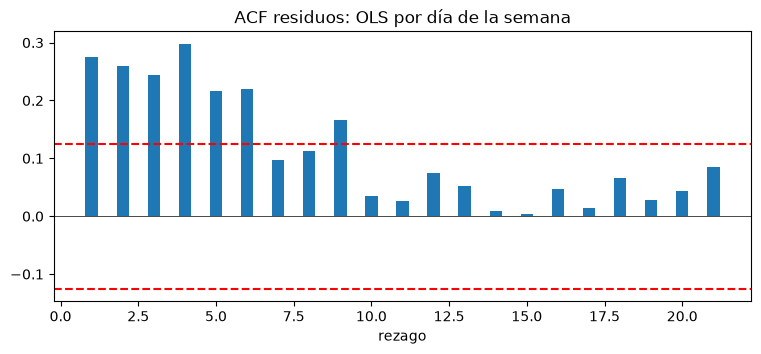

phi_hat = 0.2773412837157968


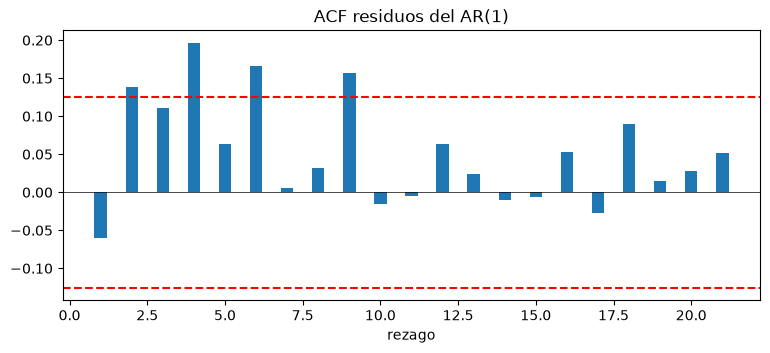

Q6 (np.float64(26.304350455034065), np.float64(7.788910266339622e-05)) Q12 (np.float64(33.95431615408554), np.float64(0.00036796487158075573))


In [24]:
DOWS = [0, 1, 2, 3, 4, 6]
def dow_dummies(idx): return np.column_stack([(idx.dayofweek == d).astype(float) for d in DOWS])

# 4.1
X = dow_dummies(tr.index)
beta = np.linalg.lstsq(X, y, rcond=None)[0]; e = y - X @ beta
plot_acf(acf(e, 21), n, 'ACF residuos: OLS por día de la semana')

# 4.2
x_, z_ = e[:-1], e[1:]
c_hat, phi_hat = np.linalg.lstsq(np.column_stack([np.ones_like(x_), x_]), z_, rcond=None)[0]
u = z_ - c_hat - phi_hat*x_
print('phi_hat =', phi_hat)
plot_acf(acf(u, 21), len(u), 'ACF residuos del AR(1)')
print('Q6', ljung_box(u, 6, 1), 'Q12', ljung_box(u, 12, 1))

In [25]:
ly = np.log(tr.values)
def ajustar(order, sorder, trend, maxiter=50):
    return SARIMAX(ly, order=order, seasonal_order=sorder, trend=trend).fit(disp=False, maxiter=maxiter)
cfg = {'S1': ((1,0,0), (1,0,0,6), 'c'), 'S2': ((0,1,1), (0,1,1,6), None)}
for nom, (o, so, tr_) in cfg.items():
    a = ajustar(o, so, tr_, 50); b = ajustar(o, so, tr_, 500)
    print(nom, 'converge(50):', a.mle_retvals['converged'], '| converge(500):', b.mle_retvals['converged'])
    display(pd.DataFrame({'maxiter50': a.params, 'maxiter500': b.params}))
MAXITER = 500
res1, res2 = ajustar(*cfg['S1'], MAXITER), ajustar(*cfg['S2'], MAXITER)
print(res1.summary().tables[1]); print(res2.summary().tables[1])

S1 converge(50): False | converge(500): True


,maxiter50,maxiter500
0,1.464926,4.241856
1,0.165562,0.135526
2,0.822816,0.514822
3,0.246968,0.218212


S2 converge(50): True | converge(500): True


,maxiter50,maxiter500
0,-0.910755,-0.910755
1,-0.683054,-0.683054
2,0.214490,0.214490


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      4.2419      0.508      8.346      0.000       3.246       5.238
ar.L1          0.1355      0.068      1.984      0.047       0.002       0.269
ar.S.L6        0.5148      0.048     10.638      0.000       0.420       0.610
sigma2         0.2182      0.017     13.109      0.000       0.186       0.251
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.9108      0.034    -26.927      0.000      -0.977      -0.844
ma.S.L6       -0.6831      0.051    -13.343      0.000      -0.783      -0.583
sigma2         0.2145      0.016     13.407      0.000       0.183       0.246


In [26]:
r1_ = res1.resid
r2_ = res2.resid[7:]          # se descartan los primeros 7 residuos
for nom, rr in [('S1', r1_), ('S2', r2_)]:
    print(nom, 'Q6', ljung_box(rr, 6, 2), 'Q12', ljung_box(rr, 12, 2))

S1 Q6 (np.float64(9.352742935057698), np.float64(0.05286259573999968)) Q12 (np.float64(23.042825161804487), np.float64(0.010589602577029398))
S2 Q6 (np.float64(3.7403567246004137), np.float64(0.4422835055212514)) Q12 (np.float64(9.53981392710057), np.float64(0.4817501694934151))


In [27]:
T0 = A.index[0]
abiertos_set = set(A.index)
tnum = lambda idx: np.asarray((idx - T0).days, float)

def lag_open(d, k):
    c = d - pd.Timedelta(days=7*k)
    while c >= T0 and c not in abiertos_set:
        c -= pd.Timedelta(days=7)
    return c if c >= T0 else pd.NaT
def lagval(d, k):
    c = lag_open(d, k); return A[c] if pd.notna(c) else np.nan
L7  = pd.Series([lagval(d, 1) for d in A.index], index=A.index)
L14 = pd.Series([lagval(d, 2) for d in A.index], index=A.index)
print(lag_open(pd.Timestamp('2011-05-09'), 1))          # debe ser 2011-04-18

MA = ma.reindex(A.index)                                # solo para la trampa (5.4)

def feats(idx, m):
    D = dow_dummies(idx)
    if m == 'M1':  return np.column_stack([tnum(idx), D])
    if m == 'M2':  return np.column_stack([D, L7.loc[idx].values, L14.loc[idx].values])
    if m == 'M2T': return np.column_stack([D, L7.loc[idx].values, L14.loc[idx].values, MA.loc[idx].values])

def ols_model(m):
    def f(hist, tg):
        X = feats(hist.index, m); ok = ~np.isnan(X).any(1)
        b = np.linalg.lstsq(X[ok], hist.values[ok], rcond=None)[0]
        return feats(tg, m) @ b
    return f

b1 = lambda hist, tg: np.full(len(tg), hist.mean())
def b2(hist, tg):
    last = hist.groupby(hist.index.dayofweek).last()
    return last.reindex(tg.dayofweek).values

CONV = []
def sarima(order, sorder, trend):
    def f(hist, tg):
        res = SARIMAX(np.log(hist.values), order=order, seasonal_order=sorder,
                      trend=trend).fit(disp=False, maxiter=MAXITER)
        CONV.append(res.mle_retvals['converged'])
        return np.exp(res.forecast(len(tg)))
    return f

MODELOS = {'B1': b1, 'B2': b2, 'M1': ols_model('M1'), 'M2': ols_model('M2'),
           'S1': sarima(*cfg['S1']), 'S2': sarima(*cfg['S2'])}
print('MODELOS listo:', list(MODELOS))

2011-04-18 00:00:00
MODELOS listo: ['B1', 'B2', 'M1', 'M2', 'S1', 'S2']


In [28]:
def rolling(f, origenes, ultimo):
    out = []
    for o in origenes:
        hist = A[A.index <= o]
        tg = A.index[(A.index > o) & (A.index <= min(o + pd.Timedelta(days=7), ultimo))]
        if len(tg) == 0: continue
        out.append(pd.DataFrame({'y': A[tg].values, 'pred': f(hist, tg), 'origen': o}, index=tg))
    return pd.concat(out)

def mae_rmse(d):
    e = d.y - d.pred
    return e.abs().mean(), np.sqrt((e**2).mean())

dom_b = pd.date_range('2011-05-01', '2011-09-30', freq='W-SUN')
dom_c = pd.date_range('2011-10-02', '2011-12-08', freq='W-SUN')

def cv_aleatorio(m, seed):
    idx = A.index[A.index <= FIN_TRAIN]
    if m != 'B1':
        idx = idx[~np.isnan(feats(idx, m)).any(1)]
    yy = A[idx].values; ys, ps = [], []
    for tri, tei in KFold(5, shuffle=True, random_state=seed).split(idx):
        h, tg = A[idx[tri]], idx[tei]
        ps.append(b1(h, tg) if m == 'B1' else ols_model(m)(h, tg)); ys.append(yy[tei])
    e = np.concatenate(ys) - np.concatenate(ps)
    return np.abs(e).mean(), np.sqrt((e**2).mean())
print('listo')

listo


In [29]:
filas, preds_c = [], {}
for nom, f in MODELOS.items():
    fila = {'modelo': nom}
    if nom in ('B1', 'M1', 'M2'):
        v = np.array([cv_aleatorio(nom, s) for s in range(10)])
        fila.update({'(a) MAE': f'{v[:,0].mean():.0f} ± {v[:,0].std(ddof=1):.0f}',
                     '(a) RMSE': f'{v[:,1].mean():.0f} ± {v[:,1].std(ddof=1):.0f}'})
    pb = rolling(f, dom_b, FIN_TRAIN); fila['(b) MAE'], fila['(b) RMSE'] = mae_rmse(pb)
    pc = rolling(f, dom_c, FIN);       fila['(c) MAE'], fila['(c) RMSE'] = mae_rmse(pc)
    preds_c[nom] = pc; filas.append(fila)
tabla5 = pd.DataFrame(filas).set_index('modelo'); display(tabla5.round(0))
print('S1/S2 convergieron siempre:', all(CONV))
tabla5.to_csv('tabla5.csv')

,(a) MAE,(a) RMSE,(b) MAE,(b) RMSE,(c) MAE,(c) RMSE
modelo,,,,,,
B1,10274 ± 51,14191 ± 47,10177.0,14812.0,22233.0,26979.0
B2,NaN,NaN,11138.0,15414.0,14563.0,18765.0
M1,9147 ± 116,12524 ± 103,9757.0,13816.0,15395.0,20455.0
M2,8359 ± 109,11763 ± 205,9172.0,13263.0,15384.0,20076.0
S1,NaN,NaN,9615.0,13655.0,16757.0,21160.0
S2,NaN,NaN,9889.0,13840.0,12777.0,16008.0


S1/S2 convergieron siempre: True


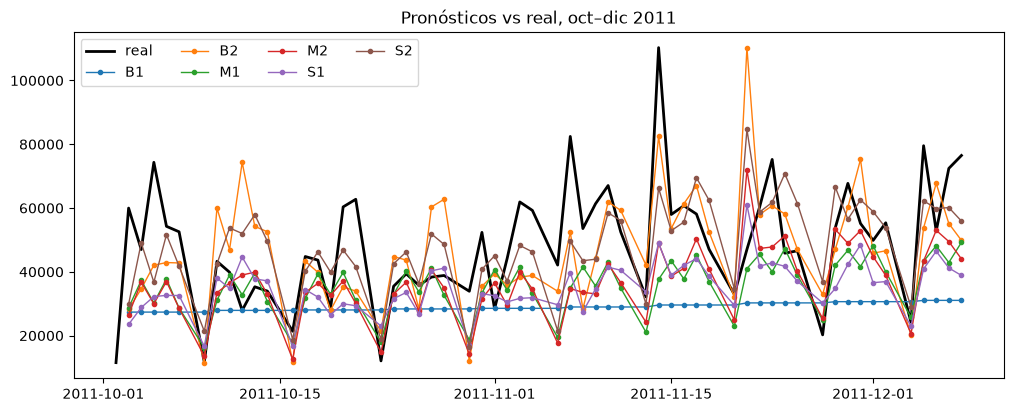

media S1 en £: 24658.450312518868


In [30]:
plt.figure(figsize=(12, 4.5))
plt.plot(A[A.index > '2011-09-30'], 'k', lw=2, label='real')
for nom, p in preds_c.items(): plt.plot(p.pred, marker='.', lw=1, label=nom)
plt.legend(ncol=4); plt.title('Pronósticos vs real, oct–dic 2011')
plt.savefig('fig_pronosticos.png', dpi=150, bbox_inches='tight'); plt.show()
print('media S1 en £:', np.exp(4.2419/((1-0.1355)*(1-0.5148))))

In [31]:
v = np.array([cv_aleatorio('M2T', s) for s in range(10)])
pbT = rolling(ols_model('M2T'), dom_b, FIN_TRAIN)
print('M2T (a) MAE, RMSE:', v.mean(0).round(0), '±', v.std(0, ddof=1).round(0))
print('M2T (b) MAE, RMSE:', np.round(mae_rmse(pbT), 0))
print('M2  (a): 8359 / 11763 | (b):', tabla5.loc['M2', ['(b) MAE', '(b) RMSE']].round(0).values)

M2T (a) MAE, RMSE: [ 7405. 10037.] ± [ 87. 145.]
M2T (b) MAE, RMSE: [ 8288. 11176.]
M2  (a): 8359 / 11763 | (b): [ 9172. 13263.]


In [32]:
c = limpiar(df); c = c[c.CustomerID.notna()].copy()
c['CustomerID'] = c.CustomerID.astype(int)
c['monto'] = c.Quantity * c.UnitPrice
c['es_venta'] = ~c.InvoiceNo.str.startswith('C')
CORTE, FIN_P = pd.Timestamp('2011-10-01'), pd.Timestamp('2011-12-09')   # FIN_P exclusivo
pre  = c[c.InvoiceDate < CORTE]
post = c[(c.InvoiceDate >= CORTE) & (c.InvoiceDate < FIN_P)]
vv = pre[pre.es_venta]

rfm = pd.DataFrame({
    'R': (CORTE - vv.groupby('CustomerID').InvoiceDate.max().dt.normalize()).dt.days,
    'F': vv.groupby('CustomerID').InvoiceNo.nunique()})
rfm['M'] = pre.groupby('CustomerID').monto.sum().reindex(rfm.index)
print('clientes en RFM:', len(rfm))
print('clientes con solo cancelaciones antes del corte:', pre.CustomerID.nunique() - len(rfm))
print('M <= 0:', (rfm.M <= 0).sum())
print(rfm.F.value_counts().head())

clientes en RFM: 3613
clientes con solo cancelaciones antes del corte: 44
M <= 0: 12
F
1    1453
2     690
3     443
4     278
5     176
Name: count, dtype: int64


In [33]:
rfm = rfm.sort_index()
rng = np.random.default_rng(2026)
rfm = rfm.iloc[rng.permutation(len(rfm))]
rfm['R_s'] = pd.qcut((-rfm.R).rank(method='first'), 5, labels=False) + 1
rfm['F_s'] = pd.qcut(rfm.F.rank(method='first'), 5, labels=False) + 1
rfm['M_s'] = pd.qcut(rfm.M.rank(method='first'), 5, labels=False) + 1
print(rfm[['R_s','F_s','M_s']].apply(pd.Series.value_counts))
print(rfm.groupby('F_s').F.agg(['min','max']))

   R_s  F_s  M_s
1  723  723  723
2  722  722  722
3  723  723  723
4  722  722  722
5  723  723  723
     min  max
F_s          
1      1    1
2      1    1
3      1    3
4      3    5
5      5  138


In [34]:
rfm['compra'] = rfm.index.isin(set(post[post.es_venta].CustomerID)).astype(int)
for col in ['R_s', 'F_s', 'M_s']:
    print(rfm.groupby(col).compra.mean().round(3).to_frame(col).T)
rfm['suma'] = rfm[['R_s', 'F_s', 'M_s']].sum(1)
auc = {'R': roc_auc_score(rfm.compra, -rfm.R), 'F': roc_auc_score(rfm.compra, rfm.F),
       'M': roc_auc_score(rfm.compra, rfm.M), 'suma': roc_auc_score(rfm.compra, rfm.suma)}
print({k: round(x, 3) for k, x in auc.items()})
print('compró en total:', rfm.compra.mean().round(3))

R_s      1      2      3      4      5
R_s  0.278  0.381  0.553  0.665  0.663
F_s      1      2      3     4      5
F_s  0.324  0.313  0.458  0.59  0.855
M_s      1      2      3      4      5
M_s  0.295  0.374  0.454  0.608  0.809
{'R': 0.673, 'F': 0.72, 'M': 0.709, 'suma': 0.735}
compró en total: 0.508


In [35]:
camp = (rfm[['R_s','F_s','M_s']] >= 4).all(axis=1)
venta_post = post.groupby('CustomerID').monto.sum()
print('% clientes campeones:', round(camp.mean(), 3))
print('% venta oct–8dic de campeones:', round(venta_post[venta_post.index.isin(camp[camp].index)].sum() / post.monto.sum(), 3))
previos = set(vv.CustomerID)
nuevos = post[~post.CustomerID.isin(previos)]
print('% venta de clientes nuevos:', round(nuevos.monto.sum() / post.monto.sum(), 3))
print('clientes nuevos:', nuevos.CustomerID.nunique(), '| venta nuevos £:', round(nuevos.monto.sum()), '| venta total £:', round(post.monto.sum()))
rfm.to_csv('rfm.csv')

% clientes campeones: 0.216
% venta oct–8dic de campeones: 0.536
% venta de clientes nuevos: 0.155
clientes nuevos: 723 | venta nuevos £: 368415 | venta total £: 2376640


In [36]:
import os; os.makedirs('figuras', exist_ok=True)
_show = plt.show; _n = [0]
def show_y_guardar(*a, **k):
    _n[0] += 1
    plt.savefig(f'figuras/fig_{_n[0]:02d}.png', dpi=150, bbox_inches='tight')
    _show(*a, **k)
plt.show = show_y_guardar

In [37]:
tabla02.to_csv('tabla02.csv'); tabla04.to_csv('tabla04.csv')
tabla5.to_csv('tabla5.csv'); bitacora.to_csv('bitacora.csv', index=False)
idx_est.round(3).to_csv('indice_estacional.csv'); rfm.to_csv('rfm.csv')
print(sorted(os.listdir('.')))

['.ipynb_checkpoints', 'Online Retail.xlsx', 'Untitled.ipynb', '__pycache__', 'bitacora.csv', 'bitacora_inicial.csv', 'fig_pronosticos.png', 'figuras', 'indice_estacional.csv', 'limpiar.py', 'retail.pkl', 'rfm.csv', 'tabla02.csv', 'tabla04.csv', 'tabla5.csv']
